# Maximum Search

In [14]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures, MinMaxScaler
from sklearn.linear_model import LinearRegression
from scipy.optimize import NonlinearConstraint, minimize

plt.style.use("dark_background")

## Import and Prepare Data

**Select either  `removal` or `recovery` as the desired Output here!**

After selecting the desired Output, the required data is imported. For simplicity, the features (Flow_C, Flow_P, and Current_Limit_P) are always imported from the cache folder here, which saves having to convert them to the correct format from the CSV files. Depending on which output variable you selected previously, either the data, quadratic features and linear model for the output variable *Average Salt Removal* or *Average Water Recovery* is loaded. The scaler used in the data preparation step is always imported i inverse transform the results.

In [ ]:
output = "removal"

In [16]:
cached_objects_data_path = os.path.join(
    os.path.dirname(os.getcwd()), "..", "cached_objects"
)

X = joblib.load(os.path.join(cached_objects_data_path, "prepared_data", "X.npy"))

if output == "removal":
    y = joblib.load(
        os.path.join(cached_objects_data_path, "prepared_data", "y_removal.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_data_path, "prepared_data", "y_label_removal.npy")
    )
    y_name = "removal"
    poly: PolynomialFeatures = joblib.load(
        os.path.join(
            cached_objects_data_path, "model_lin_reg", "removal", "poly_features.pkl"
        )
    )
    model: LinearRegression = joblib.load(
        os.path.join(
            cached_objects_data_path, "model_lin_reg", "removal", "linear_model.pkl"
        )
    )
    X_quad = joblib.load(
        os.path.join(cached_objects_data_path, "model_lin_reg", "removal", "X_quad.npy")
    )
elif output == "recovery":
    y = joblib.load(
        os.path.join(cached_objects_data_path, "prepared_data", "y_recovery.npy")
    ).reshape(-1, 1)
    y_label = joblib.load(
        os.path.join(cached_objects_data_path, "prepared_data", "y_label_recovery.npy")
    )
    y_name = "recovery"
    poly: PolynomialFeatures = joblib.load(
        os.path.join(
            cached_objects_data_path, "model_lin_reg", "recovery", "poly_features.pkl"
        )
    )
    model: LinearRegression = joblib.load(
        os.path.join(
            cached_objects_data_path, "model_lin_reg", "recovery", "linear_model.pkl"
        )
    )
    X_quad = joblib.load(
        os.path.join(
            cached_objects_data_path, "model_lin_reg", "recovery", "X_quad.npy"
        )
    )

scaler: MinMaxScaler = joblib.load(
    os.path.join(cached_objects_data_path, "prepared_data", "scaler.pkl")
)

## Optimization Step

In the following code, the actual optimization of the linear model with polynomial features is performed.

To do this, we first define a method that is then to be optimized (maximized/minimized). This method takes the three input variables, forms a polynomial from them using the already known transformer, and then makes a prediction based on the model. This prediction is then returned with a negation, as it is generally common practice to find maxima by finding the minima of the negated function.

In addition, we also need to define a method that covers an important side condition: The output value must not exceed 1.0, as neither more than 100% Salt Removal nor more than 100% water recovery are possible. As further conditions, we also specify limits that are intended to restrict the range of the incoming features and, as starting values for the search, the respective average values of the input variables.

In order to be able to pass on the linear constraint and still find a maximum, the trust region method is used here to find the maximum. The results are then finally transformed back into their original value range. 

In [17]:
# Define method which gets optimized
def objective(x):
    x = np.array(x).reshape(1, -1)
    x_quad = poly.transform(x)
    y_pred = model.predict(x_quad)[0, 0]
    return -y_pred

# Define constraint method to limit output to maximum 1.0
def y_constraint(x_raw):
    x_poly = poly.transform([x_raw])
    return 1 - model.predict(x_poly)[0]

# Set bounds to limit inout ranges
bounds = [(X[:,0].min(), X[:,0].max()),
          (X[:,1].min(), X[:,1].max()),
          (X[:,2].min(), X[:,2].max())]

# Perform the actual Maximium Search
constraint = NonlinearConstraint(y_constraint, 0, np.inf)
x0 = np.mean(X, axis=0)
res = minimize(objective, x0, bounds=bounds, method="trust-constr", constraints=[constraint])
best_val = -res.fun
best_x = res.x

# Transform results back into original value ranges
best_x_original = scaler.inverse_transform(best_x.reshape(1, -1))[0]
best_y_origional = best_val * 100

print("Optimal Flow_C", best_x_original[0])
print("Optimal Flow_P:", best_x_original[1])
print("Optimal Current_Limit_P:", best_x_original[2])
print(f"Maximum {y_label}:", best_y_origional)

Optimal Flow_C 0.7393196287131396
Optimal Flow_P: 0.3100076317130115
Optimal Current_Limit_P: 38.24264814627875
Maximum Average Water Recovery (%): 99.99997439945562


## Visualization of Results

At the bottom, the model is plotted again, but this time the *Current_Limit_P* feature is not fixed to the average value, but to the value that was obtained as the result of the maximum search. It should be noted that, for scaling reasons, the values shown here have not been transformed back to their original value range.

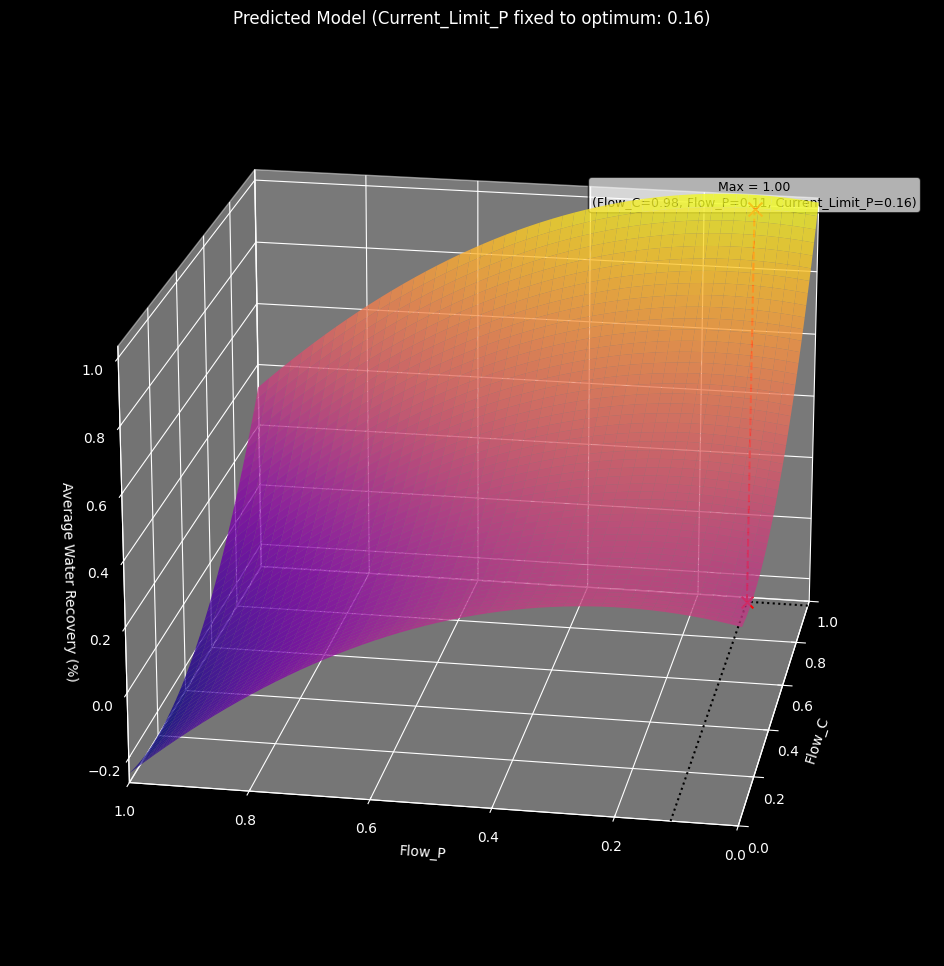

In [18]:
fig = plt.figure(figsize=(20, 12))
ax2 = fig.add_subplot(111, projection="3d")

# Setup grid for surface plot
x1 = np.linspace(X[:, 0].min(), X[:, 0].max(), 50)
x2 = np.linspace(X[:, 1].min(), X[:, 1].max(), 50)
x1_grid, x2_grid = np.meshgrid(x1, x2, indexing="xy")
# Fix x3 at the optimal value
x3_fixed = best_x[2]

# Predict on the grid for visualization
X_grid = np.column_stack([
    x1_grid.ravel(),
    x2_grid.ravel(),
    np.full_like(x1_grid.ravel(), x3_fixed)
])
y_grid = model.predict(poly.transform(X_grid)).reshape(x1_grid.shape)

# Plot the surface
ax2.plot_surface(x1_grid, x2_grid, y_grid, cmap="plasma", alpha=0.8)

# Set maximum marker
best_y = model.predict(poly.transform(best_x.reshape(1, -1)))[0, 0]
ax2.scatter(best_x[0], best_x[1], best_y,
            color="red", s=100, marker="x")

# Set limits
ax2.set_xlim(X[:,0].min(), X[:,0].max())
ax2.set_ylim(X[:,1].min(), X[:,1].max())
ax2.set_zlim(y_grid.min(), y_grid.max())
zmin = ax2.get_zlim()[0]

# Print Vertical line to XY-plane
ax2.plot([best_x[0], best_x[0]], [best_x[1], best_x[1]],
         [zmin, best_y], color="red", linestyle="--")

# Print Projection on XY-plane
ax2.scatter(best_x[0], best_x[1], zmin, color="red", s=70,
            marker="x")

# Grey guide lines along axes
ax2.plot([ax2.get_xlim()[0], best_x[0]], [best_x[1], best_x[1]],
         [zmin, zmin], color="black", linestyle=":")
ax2.plot([best_x[0], best_x[0]], [ax2.get_ylim()[0], best_x[1]],
         [zmin, zmin], color="black", linestyle=":", alpha=1.0)

# Create Annotation
ax2.text(best_x[0], best_x[1], best_y,
         f"Max = {best_y:.2f}\n(Flow_C={best_x[0]:.2f}, Flow_P={best_x[1]:.2f}, Current_Limit_P={best_x[2]:.2f})",
         color="black", fontsize=9, ha="center", va="bottom",
         bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", alpha=0.7))

ax2.set_xlabel("Flow_C")
ax2.set_ylabel("Flow_P")
ax2.set_zlabel(f"{y_label}")
ax2.set_title(f"Predicted Model (Current_Limit_P fixed to optimum: {x3_fixed:.2f})")
ax2.view_init(elev=20, azim=190)

plt.show()
